# Challenge 1 — Data profiling, split y EDA (Wine)

Este notebook reproduce, con un dataset diferente (**Wine**), el flujo de los notebooks 1 y 2 del ejemplo de Breast Cancer.

Responsabilidades:

- cargar `wine.csv`;
- comprobar su estructura y calidad básica (profiling);
- separar `train` y `test` de forma estratificada y reproducible;
- guardar los conjuntos **sin aplicar transformaciones**;
- hacer el EDA **únicamente sobre `train`**;
- guardar el contrato de datos (`data_contract.json`).

> El conjunto de prueba se crea aquí, pero no se explora ni se usa hasta el notebook 3.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_RAW = PROJECT_DIR / "data" / "raw"
DATA_PROCESSED = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"
for directory in (DATA_RAW, DATA_PROCESSED, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

PROJECT_DIR

PosixPath('/home/claude/work/extracted/talleres-ia-2026/semana6/wine_challenge')

## Fuente de datos: `wine.csv`

Wine (UCI *Wine Recognition*) contiene 178 vinos italianos de tres cultivares, descritos por 13 medidas químicas. El archivo `wine.csv` no se entrega en el repositorio: se genera una sola vez a partir de la copia que incluye scikit-learn, con el mismo formato que `breast_cancer.csv` (variables predictoras + columna `target`).

In [3]:
WINE_CSV = DATA_RAW / "wine.csv"

if not WINE_CSV.exists():
    wine = load_wine(as_frame=True)
    wine.frame.to_csv(WINE_CSV, index=False)
    print("Archivo creado:", WINE_CSV.relative_to(PROJECT_DIR))
else:
    print("Archivo existente:", WINE_CSV.relative_to(PROJECT_DIR))

TARGET_NAMES = [str(name) for name in load_wine().target_names]   # ['class_0', 'class_1', 'class_2']
TARGET_NAMES


Archivo existente: data/raw/wine.csv


['class_0', 'class_1', 'class_2']

## Carga y contrato inicial

In [4]:
df = pd.read_csv(WINE_CSV)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas predictoras: {df.shape[1] - 1}")
print("Duplicados:", df.duplicated().sum())
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Distribución de la clase:")
feature_names = df.drop(columns="target").columns.tolist()
display(df["target"].value_counts().sort_index().rename(index=dict(enumerate(TARGET_NAMES))))

Filas: 178
Columnas predictoras: 13
Duplicados: 0
Valores faltantes: 0
Distribución de la clase:


target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64

In [6]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})
profile

,dtype,missing,unique,min,max
alcohol,float64,0,126,11.03,14.83
malic_acid,float64,0,133,0.74,5.80
ash,float64,0,79,1.36,3.23
alcalinity_of_ash,float64,0,63,10.60,30.00
magnesium,float64,0,53,70.00,162.00
total_phenols,float64,0,97,0.98,3.88
flavanoids,float64,0,132,0.34,5.08
nonflavanoid_phenols,float64,0,39,0.13,0.66
proanthocyanins,float64,0,101,0.41,3.58
color_intensity,float64,0,132,1.28,13.00


## Split reproducible

In [7]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Proporción por clase en train:", train_df["target"].value_counts(normalize=True).sort_index().round(3).tolist())
print("Proporción por clase en test: ", test_df["target"].value_counts(normalize=True).sort_index().round(3).tolist())

Train: (142, 14)
Test: (36, 14)
Proporción por clase en train: [0.331, 0.401, 0.268]
Proporción por clase en test:  [0.333, 0.389, 0.278]


In [8]:
train_df.to_csv(DATA_PROCESSED / "train.csv", index=False)
test_df.to_csv(DATA_PROCESSED / "test.csv", index=False)

contract = {
    "dataset": "Wine Recognition (UCI) — scikit-learn load_wine",
    "target": "target",
    "target_names": TARGET_NAMES,
    "features": feature_names,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "sklearn_version": sklearn.__version__,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2), encoding="utf-8"
)
print("Datos y contrato guardados.")

Datos y contrato guardados.


---
# EDA (solo `train`)

A partir de aquí **solo se usa `train.csv`**. El propósito es comprender los datos y justificar decisiones posteriores, no modificar todavía las variables.

In [9]:
train_df = pd.read_csv(DATA_PROCESSED / "train.csv")
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
target = contract["target"]
X_train = train_df.drop(columns=target)
y_train = train_df[target]
print(train_df.shape)
train_df.head()

(142, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,13.28,1.64,2.84,15.5,110.0,2.60,2.68,0.34,1.36,4.60,1.09,2.78,880.0,0
1,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.19,2.71,1285.0,0
2,13.39,1.77,2.62,16.1,93.0,2.85,2.94,0.34,1.45,4.80,0.92,3.22,1195.0,0
3,13.75,1.73,2.41,16.0,89.0,2.60,2.76,0.29,1.81,5.60,1.15,2.90,1320.0,0
4,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0,2


## Distribución de la variable objetivo

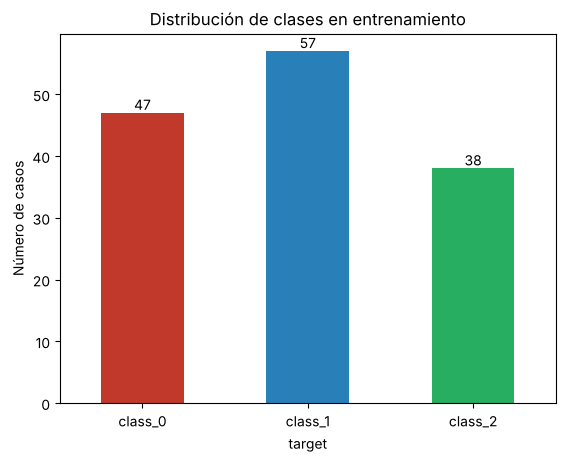

{0: 0.331, 1: 0.401, 2: 0.268}


In [10]:
counts = y_train.value_counts().sort_index()
ax = counts.plot.bar(color=["#c0392b", "#2980b9", "#27ae60"])
ax.set_xticklabels(contract["target_names"], rotation=0)
ax.set_ylabel("Número de casos")
ax.set_title("Distribución de clases en entrenamiento")
for i, v in enumerate(counts):
    ax.text(i, v + 0.5, str(v), ha="center")
plt.savefig(REPORTS_DIR / "eda_class_distribution.png", dpi=120, bbox_inches="tight")
plt.show()
print((counts / counts.sum()).round(3).to_dict())

## Distribuciones y escala de las variables

In [11]:
X_train.describe().T[["mean", "std", "min", "50%", "max"]].sort_values("std", ascending=False).head(10)

,mean,std,min,50%,max
proline,739.478873,301.499014,278.00,673.500,1515.00
magnesium,99.633803,14.937448,70.00,97.000,162.00
alcalinity_of_ash,19.625352,3.380848,10.60,19.500,30.00
color_intensity,4.989648,2.334947,1.28,4.640,13.00
malic_acid,2.340000,1.101285,0.74,1.810,5.80
flavanoids,1.985352,0.951952,0.34,2.135,3.74
alcohol,12.971479,0.802521,11.03,13.010,14.83
od280/od315_of_diluted_wines,2.606197,0.689650,1.27,2.780,3.92
total_phenols,2.273732,0.621454,0.98,2.335,3.88
proanthocyanins,1.600211,0.579777,0.42,1.560,3.58


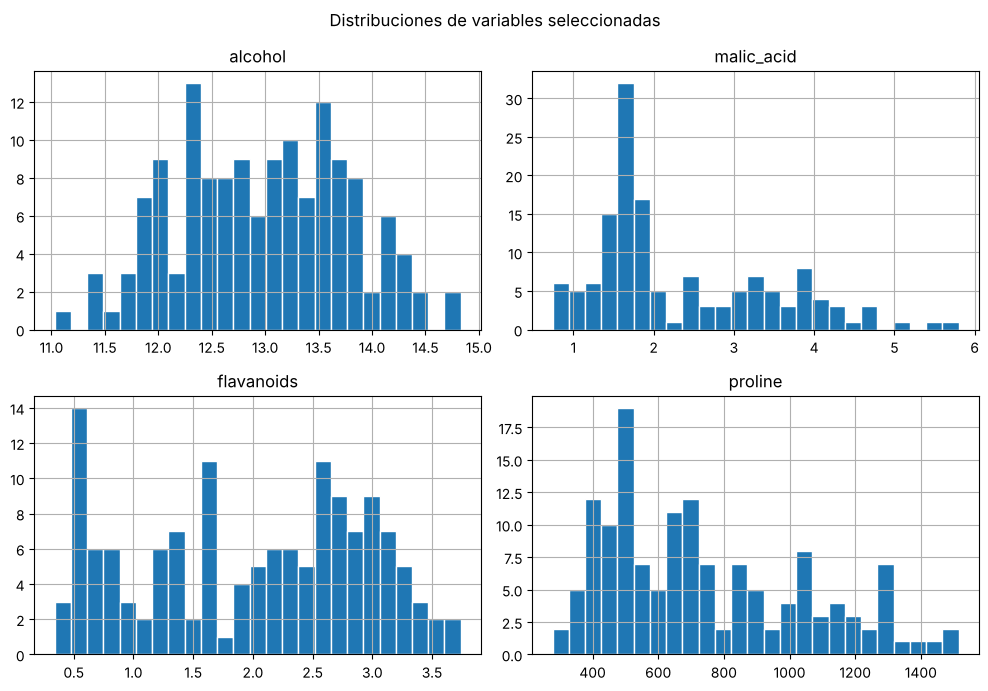

In [12]:
selected = ["alcohol", "malic_acid", "flavanoids", "proline"]
train_df[selected].hist(figsize=(10, 7), bins=25, edgecolor="white")
plt.suptitle("Distribuciones de variables seleccionadas")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

## Relación con la clase

El objetivo tiene **tres clases nominales**, por lo que la correlación lineal con `target` (que trata la clase como un número ordenado) no es adecuada. En su lugar se usa el **estadístico F de ANOVA** (`f_classif`): cuanto mayor es, más separa la variable a las tres clases.

,F,p_value
flavanoids,224.760551,2.761003e-44
proline,161.459538,5.651955e-37
od280/od315_of_diluted_wines,144.758527,1.041705e-34
color_intensity,103.897340,2.538020e-28
alcohol,98.468093,2.315697e-27
hue,79.531558,9.442918e-24
total_phenols,72.338568,2.939256e-22
malic_acid,29.088066,2.799960e-11
alcalinity_of_ash,27.518692,8.540681e-11
proanthocyanins,23.347278,1.811283e-09


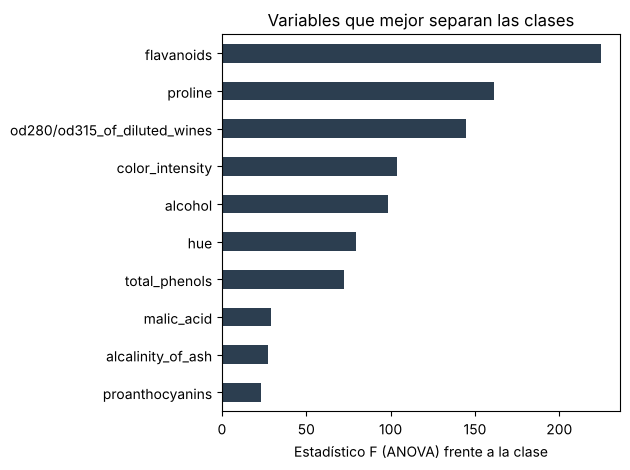

In [13]:
f_values, p_values = f_classif(X_train, y_train)
anova = pd.DataFrame({"F": f_values, "p_value": p_values}, index=X_train.columns).sort_values("F", ascending=False)
display(anova.head(10))

anova["F"].head(10).sort_values().plot.barh(color="#2c3e50")
plt.xlabel("Estadístico F (ANOVA) frente a la clase")
plt.title("Variables que mejor separan las clases")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_anova.png", dpi=120, bbox_inches="tight")
plt.show()

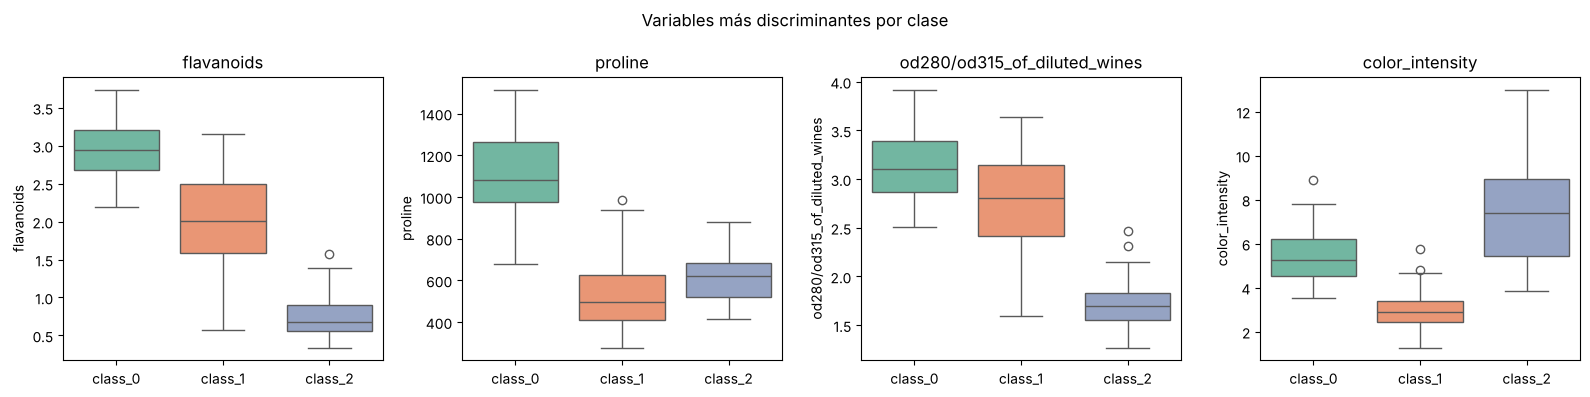

In [14]:
top_features = anova.head(4).index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, feature in zip(axes, top_features):
    sns.boxplot(data=train_df, x="target", y=feature, ax=ax, hue="target", palette="Set2", legend=False)
    ax.set_xticks(range(3))
    ax.set_xticklabels(contract["target_names"])
    ax.set_xlabel("")
    ax.set_title(feature)
plt.suptitle("Variables más discriminantes por clase")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_boxplots.png", dpi=120, bbox_inches="tight")
plt.show()

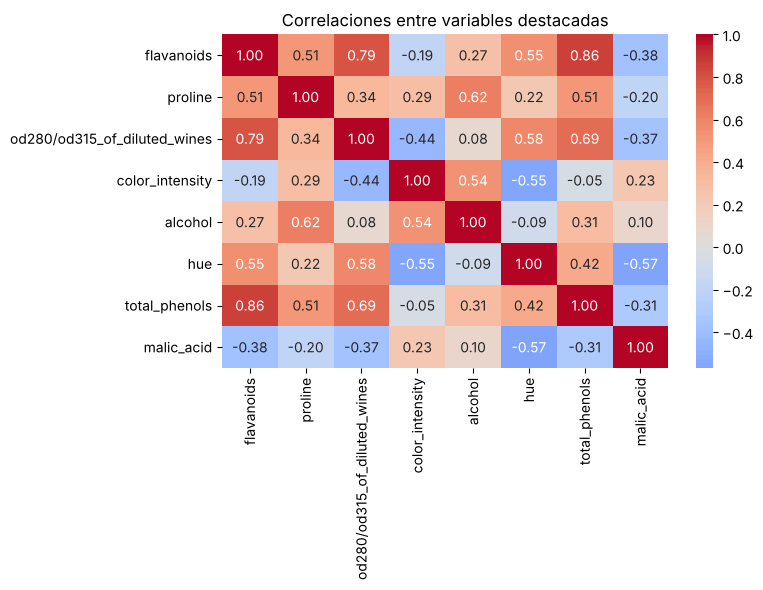

Pares de variables más correlacionados (|r|):
total_phenols  flavanoids                      0.861
flavanoids     od280/od315_of_diluted_wines    0.786
total_phenols  od280/od315_of_diluted_wines    0.695
flavanoids     proanthocyanins                 0.657
alcohol        proline                         0.621
dtype: float64


In [15]:
top8 = anova.head(8).index
plt.figure(figsize=(8, 6))
sns.heatmap(train_df[top8].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlaciones entre variables destacadas")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_correlations.png", dpi=120, bbox_inches="tight")
plt.show()

corr = train_df[feature_names].corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False))
print("Pares de variables más correlacionados (|r|):")
print(pairs.head(5).round(3))

In [16]:
scale_ratio = X_train.std().max() / X_train.std().min()
print(f"Desviación típica máxima: {X_train.std().max():.2f} ({X_train.std().idxmax()})")
print(f"Desviación típica mínima: {X_train.std().min():.3f} ({X_train.std().idxmin()})")
print(f"Cociente máx/mín: {scale_ratio:,.0f}")

Desviación típica máxima: 301.50 (proline)
Desviación típica mínima: 0.119 (nonflavanoid_phenols)
Cociente máx/mín: 2,529


## Decisiones derivadas del EDA

| Hallazgo (solo `train`) | Decisión |
|---|---|
| 142 filas de entrenamiento, 13 variables numéricas, **sin duplicados ni valores faltantes**. | No hace falta limpiar datos, pero el pipeline incluirá imputación por la mediana para soportar datos futuros incompletos. |
| Clases moderadamente desbalanceadas: 33.1 % / 40.1 % / 26.8 % (`class_0`, `class_1`, `class_2`). | Split y validación cruzada **estratificados**; además de accuracy se reportarán `f1_macro` y `roc_auc_ovr`. |
| **Escalas muy distintas**: la desviación típica va de 0.12 (`nonflavanoid_phenols`) a 301 (`proline`), un cociente ≈2 500. | Estandarizar para regresión logística y KNN (la regularización y las distancias estarían dominadas por `proline`). El árbol no lo necesita. |
| Las variables que más separan las clases (ANOVA F) son `flavanoids` (F≈225), `proline` (161), `od280/od315` (145), `color_intensity` (104) y `alcohol` (98). | El problema parece **muy separable**; se esperan métricas altas y hay que desconfiar de diferencias minúsculas entre modelos. |
| Variables fuertemente correlacionadas: `total_phenols`–`flavanoids` (r≈0.86), `flavanoids`–`od280/od315` (0.79). | No impide entrenar, pero hay que ser cautelosos al interpretar coeficientes o importancias (multicolinealidad). |
| Conjunto pequeño: 142 ejemplos de entrenamiento y solo 36 de prueba. | Validación cruzada de 5 folds con semilla fija; la métrica final en `test` será ruidosa (un solo error ≈ 2.8 puntos porcentuales). |

> La correlación lineal con la clase no se usó como criterio porque `target` es una variable nominal de tres categorías; se usó ANOVA F en su lugar.